# CarbonCast — 96-hour carbon-intensity forecasts for any region

This notebook walks through running **CarbonCast** predictions with the pre-trained (saved) second-tier models that ship with the repo. You pick a region and an emission-factor type, and the notebook:

1. checks your environment,
2. loads the region's configuration and data,
3. explains (and sanity-checks) how carbon intensity is computed,
4. shows how the model inputs are built (feature engineering, train/val/test split, scaling),
5. loads the saved CNN-LSTM model,
6. produces a **96-hour forecast for any start date** you choose,
7. reproduces the paper-style evaluation over Jul–Dec 2021 and compares it with a simple baseline,
8. saves forecasts to CSV, and optionally runs every region in one go.

### How CarbonCast works (in one paragraph)
CarbonCast has two tiers. **Tier 1** (`src/firstTierForecasts.py`) uses small ANNs + weather forecasts to predict 96 hours of electricity production *per source* (coal, gas, wind, solar…). **Tier 2** (`src/secondTierForecasts.py`) is a CNN-LSTM that takes the last 24 h of carbon intensity, calendar features, and the 96-h weather + tier-1 source forecasts, and predicts the next 24 h of carbon intensity. It is applied 4 times in a row (feeding its own predictions back in) to cover 96 hours. The repo already contains the tier-1 outputs (`data/<REGION>/<REGION>_96hr_forecasts*.csv`) and trained tier-2 models (`saved_second_tier_models/`), so **you only need tier 2 to get predictions** — that is what this notebook runs.

```
weather forecasts ─┐
                   ├─► Tier 1 (ANN per source) ─► 96h source-production forecasts ─┐
historical mix  ───┘                                                               ├─► Tier 2 (CNN-LSTM) ─► 96h CI forecast
historical carbon intensity + calendar features ───────────────────────────────────┘
```

## 0. Environment setup (do once, in a terminal)

The saved models were created with **TensorFlow/Keras 2.9**, and the repo pins its versions in `requirements.txt`. TensorFlow 2.9 needs **Python 3.7–3.10**, so the safest route is a dedicated environment:

```bash
conda create -n carboncast python=3.9 -y
conda activate carboncast
pip install -U -r requirements.txt
pip install notebook ipykernel
python -m ipykernel install --user --name carboncast
```
Then open this notebook with the `carboncast` kernel.

> Newer TensorFlow versions (2.13+, Keras 3) may still load the `.h5` models via the fallback in Section 5, but the original script `secondTierForecasts.py` will not import on them (it uses `keras.layers.convolutional`). If anything misbehaves, use the pinned environment above.

In [ ]:
import sys, os, re, json, glob, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

print("Python     :", sys.version.split()[0])
print("numpy      :", np.__version__)
print("pandas     :", pd.__version__)
try:
    import tensorflow as tf
    print("tensorflow :", tf.__version__)
except ImportError:
    tf = None
    print("tensorflow : NOT INSTALLED -> run `pip install -U -r requirements.txt` (see Section 0)")

def read_utc_csv(path, index_col="UTC time"):
    # Read a CarbonCast CSV and make 'UTC time' tz-naive UTC (some regions, e.g. DE, store '+00:00')
    df = pd.read_csv(path)
    df[index_col] = pd.to_datetime(df[index_col], utc=True).dt.tz_localize(None)
    return df.set_index(index_col)


## 1. Choose what to forecast

Set the parameters below. Everything else in the notebook adapts to them.

* `REGION` — one of the regions that has a saved model (listed when you run the next cell): `CISO, PJM, ERCO, ISNE, NYISO, FPL, BPAT` (US), `DE, NL, ES, SE, PL` (Europe), `AUS_QLD` (Australia).
* `CEF_TYPE` — `"lifecycle"` (operational + infrastructure emissions) or `"direct"` (operational only). Each has its own saved model.
* `FORECAST_START` — the UTC date (midnight) at which a single 96-h forecast in Section 6 starts. The bundled data covers 2020-01-01 → 2021-12-31, so valid starts are **2020-01-02 … 2021-12-29** (actuals are available to compare against up to a 2021-12-28 start).

In [2]:
# ======================= PARAMETERS =======================
REGION         = "PL"            # e.g. "CISO", "DE", "ERCO", "AUS_QLD" ...
CEF_TYPE       = "lifecycle"     # "lifecycle" or "direct"
FORECAST_START = "2021-10-15"    # UTC date (midnight) for the single 96h forecast in Section 6
SAVE_RESULTS   = True            # write forecast CSVs to CI_forecast_data/<REGION>/
# ===========================================================

# Locate the repo root (the folder that contains src/ and data/)
NOTEBOOK_DIR = Path.cwd()
REPO = NOTEBOOK_DIR / "CarbonCast"
for cand in [REPO, *REPO.parents]:
    if (cand / "src" / "secondTierConfig.json").exists() and (cand / "data").exists():
        REPO = cand
        break
else:
    raise FileNotFoundError("Could not find the CarbonCast repo root. Put this notebook in the repo folder "
                            "(next to src/ and data/) or set REPO = Path(r'C:\\path\\to\\CarbonCast').")
SRC = REPO / "src"

available = sorted(Path(p).stem for p in glob.glob(str(REPO / "saved_second_tier_models" / CEF_TYPE / "*.h5")))
print(f"Regions with a saved {CEF_TYPE} model:", available)
assert CEF_TYPE in ("lifecycle", "direct"), "CEF_TYPE must be 'lifecycle' or 'direct'"
assert REGION in available, f"No saved {CEF_TYPE} model for {REGION}"

Regions with a saved lifecycle model: ['AUS_QLD', 'BPAT', 'CISO', 'DE', 'ERCO', 'ES', 'FPL', 'ISNE', 'NL', 'NYISO', 'PJM', 'PL', 'SE']


## 2. Load the configuration

`src/secondTierConfig.json` holds global settings (window sizes, test/validation lengths, model locations) and one block per region (input files, number of features). The file contains `//` comments, so it is read with `json5` (falls back to stripping comments if `json5` isn't installed). File paths inside it are relative to `src/`, so they are resolved from there.

In [3]:
def load_config(path):
    text = Path(path).read_text(encoding="utf-8")
    try:
        import json5
        return json5.loads(text)
    except ImportError:
        # strip // comments (not inside strings) and trailing commas
        text = re.sub(r'("(?:\\.|[^"\\])*")|//[^\n]*', lambda m: m.group(1) or "", text)
        text = re.sub(r",\s*([}\]])", r"\1", text)
        return json.loads(text)

cfg  = load_config(SRC / "secondTierConfig.json")
rcfg = cfg[REGION]

def src_path(p):  # config paths are relative to src/
    return (SRC / p).resolve()

TRAINING_WINDOW_HOURS   = cfg["TRAINING_WINDOW_HOURS"]        # 24 h of history as model input
PREDICTION_WINDOW_HOURS = cfg["PREDICTION_WINDOW_HOURS"]      # 96 h forecast horizon
MAX_PRED_HOURS          = cfg["MAX_PREDICTION_WINDOW_HOURS"]  # 96 rows per forecast block in the input file
SLIDING                 = cfg["MODEL_SLIDING_WINDOW_LEN"]     # a new forecast every 24 h
NUM_TEST_DAYS           = cfg["NUM_TEST_DAYS"]                # 181 (Jul-Dec 2021)
NUM_VAL_DAYS            = cfg["NUM_VAL_DAYS"]                 # 181 (Jan-Jun 2021)
BUFFER_DAYS             = (PREDICTION_WINDOW_HOURS - 24) // 24  # 3 extra days so the last 96h window has actuals

EMISSIONS_FILE = src_path(rcfg["LIFECYCLE_CEF_IN_FILE_NAME" if CEF_TYPE == "lifecycle" else "DIRECT_CEF_IN_FILE_NAME"])
FORECAST_FILE  = src_path(rcfg["FORECAST_IN_FILE_NAME"])
MODEL_FILE     = REPO / "saved_second_tier_models" / CEF_TYPE / f"{REGION}.h5"
N_HIST_FEATS   = rcfg["NUM_FEATURES"]           # carbon_intensity + 5 calendar features = 6
N_FCST_FEATS   = rcfg["NUM_FORECAST_FEATURES"]  # weather + tier-1 source forecasts used by the model
START_COL      = rcfg["START_COL"]

print(json.dumps(rcfg, indent=2))

{
  "LIFECYCLE_CEF_IN_FILE_NAME": "../data/PL/PL_lifecycle_emissions.csv",
  "DIRECT_CEF_IN_FILE_NAME": "../data/PL/PL_direct_emissions.csv",
  "FORECAST_IN_FILE_NAME": "../data/PL/PL_96hr_forecasts.csv",
  "LIFECYCLE_CEF_OUT_FILE_NAME_PREFIX": "../CI_forecast_data/PL/PL_lifecycle_96hr_CI_forecasts",
  "DIRECT_CEF_OUT_FILE_NAME_PREFIX": "../CI_forecast_data/PL/PL_direct_96hr_CI_forecasts",
  "LOCAL_TIMEZONE": "CET",
  "NUM_FEATURES": 6,
  "NUM_FORECAST_FEATURES": 12,
  "START_COL": 1
}


## 3. The historical data and how carbon intensity is calculated

`data/<REGION>/<REGION>_<lifecycle|direct>_emissions.csv` has one row per hour (UTC, 2020–2021): the region's **carbon intensity** (gCO₂eq/kWh) followed by the electricity produced by each source (MW).

Average carbon intensity is the production-weighted average of the sources' carbon emission factors (CEF):

$$CI_{avg} = \frac{\sum_i E_i \cdot CEF_i}{\sum_i E_i}$$

The CEFs below are the ones used in `src/carbonIntensityCalculator.py`. As a sanity check we recompute CI from the source columns and compare it with the stored column.

In [4]:
emis = read_utc_csv(EMISSIONS_FILE)
emis = emis.drop(columns=[c for c in emis.columns if c.startswith("Unnamed")])
source_cols = [c for c in emis.columns if c != "carbon_intensity"]
print(f"{len(emis)} hourly rows: {emis.index[0]} -> {emis.index[-1]}")
print("Sources:", source_cols)
display(emis.head())

17544 hourly rows: 2020-01-01 00:00:00 -> 2021-12-31 23:00:00
Sources: ['wind', 'hydro', 'biomass', 'nat_gas', 'oil', 'coal', 'solar']


,carbon_intensity,wind,hydro,biomass,nat_gas,oil,coal,solar
UTC time,,,,,,,,
2020-01-01 00:00:00,611.40,2503,161,253,1264,220,8815,0
2020-01-01 01:00:00,609.51,2500,161,248,1243,220,8667,0
2020-01-01 02:00:00,609.55,2396,160,250,1228,220,8366,0
2020-01-01 03:00:00,611.89,2305,159,255,1236,220,8256,0
2020-01-01 04:00:00,610.27,2337,159,262,1236,220,8264,0


Recomputed vs stored CI: mean |diff| = 0.002 g/kWh, max = 0.00 (small differences come from missing-hour filling in the original script)


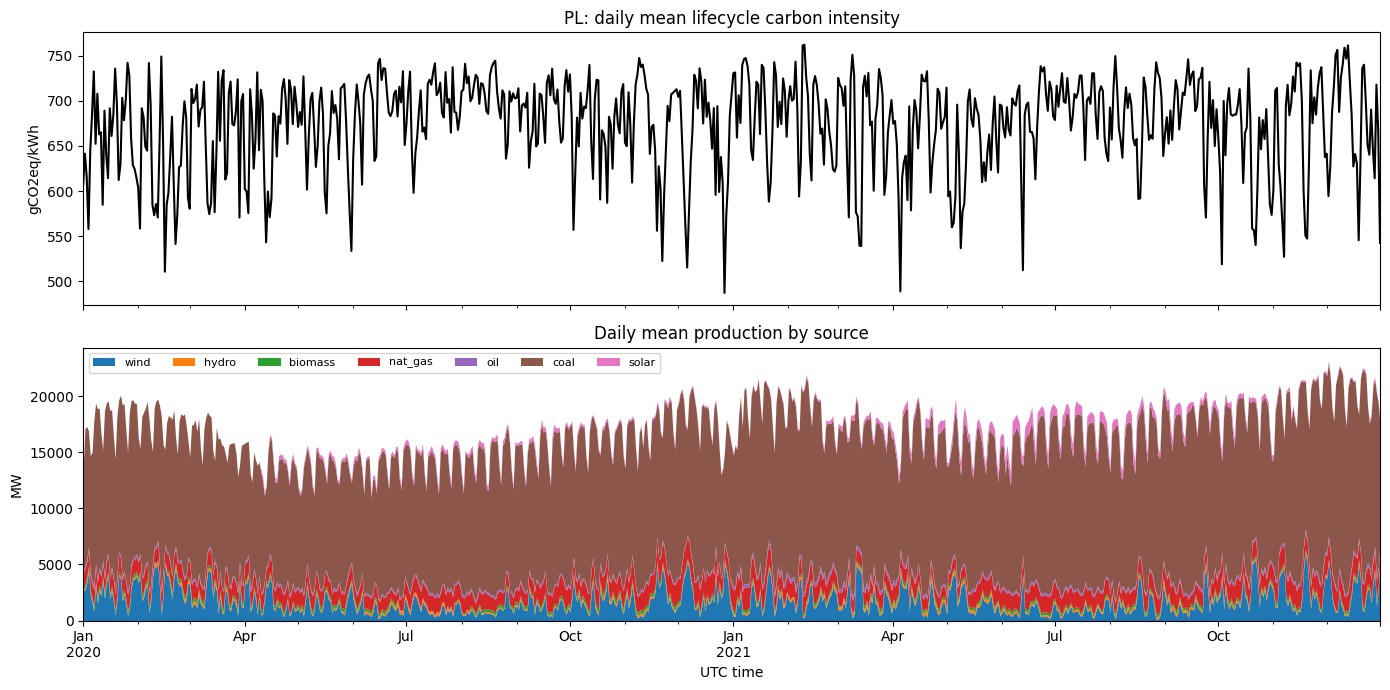

In [5]:
CEF = {
    "lifecycle": {"coal": 820, "biomass": 230, "nat_gas": 490, "geothermal": 38, "hydro": 24, "nuclear": 12,
                  "oil": 650, "solar": 45, "unknown": 700, "other": 700, "wind": 11},
    "direct":    {"coal": 760, "biomass": 0, "nat_gas": 370, "geothermal": 0, "hydro": 0, "nuclear": 0,
                  "oil": 406, "solar": 0, "unknown": 575, "other": 575, "wind": 0},
}[CEF_TYPE].copy()
if REGION == "SE" and CEF_TYPE == "lifecycle":       # special case in carbonIntensityCalculator.py
    CEF["unknown"] = CEF["other"] = 292.9

unknown_src = [c for c in source_cols if c not in CEF]
if unknown_src:
    print("No emission factor for", unknown_src, "- left out of the recomputation below")
known = [c for c in source_cols if c in CEF]
prod = emis[source_cols].clip(lower=0).fillna(0)
ci_recomputed = (prod[known] * pd.Series(CEF)[known]).sum(axis=1) / prod[known].sum(axis=1)
diff = (ci_recomputed - emis["carbon_intensity"]).abs()
print(f"Recomputed vs stored CI: mean |diff| = {diff.mean():.3f} g/kWh, max = {diff.max():.2f} "
      "(small differences come from missing-hour filling in the original script)")

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
emis["carbon_intensity"].resample("D").mean().plot(ax=axes[0], color="k")
axes[0].set_ylabel("gCO2eq/kWh"); axes[0].set_title(f"{REGION}: daily mean {CEF_TYPE} carbon intensity")
(prod.resample("D").mean()).plot.area(ax=axes[1], linewidth=0)
axes[1].set_ylabel("MW"); axes[1].set_title("Daily mean production by source")
axes[1].legend(ncol=len(source_cols), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## 4. The forecast inputs and how the model sees them

### 4.1 Weather + tier-1 source forecasts
`<REGION>_96hr_forecasts*.csv` is organised in **blocks of 96 rows**: block *k* is the 96-hour forecast issued for the period starting at `2020-01-01 + k days` (so consecutive blocks overlap by 72 h). Each row has 5 aggregated weather forecasts (wind speed, temperature, dew point, solar irradiance, precipitation) followed by tier-1 production forecasts per source. The model uses the first `NUM_FORECAST_FEATURES` columns.

In [6]:
fc = read_utc_csv(FORECAST_FILE)
assert len(fc) % MAX_PRED_HOURS == 0, "forecast file should contain whole 96-row blocks"
n_blocks = len(fc) // MAX_PRED_HOURS
fc_feats = list(fc.columns[:N_FCST_FEATS])
block_start = fc.index[::MAX_PRED_HOURS]
print(f"{n_blocks} forecast blocks, first starts {block_start[0].date()}, last starts {block_start[-1].date()}")
print(f"Model uses {N_FCST_FEATS} forecast features:", fc_feats)
if len(fc.columns) > N_FCST_FEATS:
    print("Ignored columns:", list(fc.columns[N_FCST_FEATS:]))
display(fc.iloc[[0, 1, 95, 96]])

728 forecast blocks, first starts 2020-01-01, last starts 2021-12-28
Model uses 12 forecast features: ['forecast_avg_wind_speed_wMean', 'forecast_avg_temperature_wMean', 'forecast_avg_dewpoint_wMean', 'forecast_avg_dswrf_wMean', 'forecast_avg_precipitation_wMean', 'avg_biomass_production_forecast', 'avg_coal_production_forecast', 'avg_hydro_production_forecast', 'avg_nat_gas_production_forecast', 'avg_oil_production_forecast', 'avg_solar_production_forecast', 'avg_wind_production_forecast']


,forecast_avg_wind_speed_wMean,forecast_avg_temperature_wMean,forecast_avg_dewpoint_wMean,forecast_avg_dswrf_wMean,forecast_avg_precipitation_wMean,avg_biomass_production_forecast,avg_coal_production_forecast,avg_hydro_production_forecast,avg_nat_gas_production_forecast,avg_oil_production_forecast,avg_solar_production_forecast,avg_wind_production_forecast
UTC time,,,,,,,,,,,,
2020-01-01 00:00:00,4.049083,273.328952,270.310853,0.0,0.003355,254.86106,9955.22768,142.37101,1362.97807,222.03704,0.0,2367.00006
2020-01-01 01:00:00,4.115209,273.072865,269.347545,0.0,0.000719,257.25342,9846.06777,140.27802,1373.33901,224.16581,0.0,2358.00007
2020-01-04 23:00:00,2.805696,271.735835,269.202366,0.0,0.043523,266.37028,10523.87905,126.78681,1395.27693,225.97727,0.0,2002.57437
2020-01-02 00:00:00,3.838320,273.405967,267.032472,0.0,0.000000,262.33997,10595.34204,132.54594,1407.99514,228.43771,0.0,2481.00003


### 4.2 Feature engineering, split, and scaling (same as `secondTierForecasts.py`)

* **Historical features (6):** `carbon_intensity`, `hour_sin`, `hour_cos`, `month_sin`, `month_cos` (computed from the timestamp over a 365.25-day year), `weekend`.
* **Split** (the saved models were trained this way): train = 2020, validation = Jan–Jun 2021, test = Jul–Dec 2021 (+3 buffer days so the last 96-h window has actuals). Forecast blocks are split the same way.
* **Scaling:** min–max to [0, 1] using **training-set** min/max only (a column that is constant in training is left unscaled). Historical and forecast features are scaled separately.
* **Missing values:** forward-filled from the previous hour.

**Input/output alignment the model was trained with:** to predict day *d+1*, the model gets the 24 hours of day *d* (CI + calendar features) together with the forecast-block rows for those same 24 hours, taken from the block issued at the start of day *d*. For the 96-h horizon it repeats this 4 times with the same block (rows 0–23, 24–47, 48–71, 72–95), each time appending its own 24-h prediction to the history.

In [7]:
def calendar_features(index):
    # Same calendar features as secondTierForecasts.addDateTimeFeatures
    idx = pd.DatetimeIndex(index)
    secs = np.asarray((idx - pd.Timestamp("1970-01-01")).total_seconds(), dtype=float)
    sec_in_year = 365.25 * 24 * 3600
    return pd.DataFrame({
        "hour_sin":  np.sin(idx.hour * 2 * np.pi / 24),
        "hour_cos":  np.cos(idx.hour * 2 * np.pi / 24),
        "month_sin": np.sin(secs * 2 * np.pi / sec_in_year),
        "month_cos": np.cos(secs * 2 * np.pi / sec_in_year),
        "weekend":   (idx.weekday >= 5).astype(float),
    }, index=idx)

def fit_minmax(train_values):
    # min-max from the training rows; constant columns are left unscaled (as in common.scaleDataset)
    mn, mx = train_values.min(axis=0), train_values.max(axis=0)
    const = (mx - mn) == 0
    return mn, np.where(const, 1.0, mx - mn), const

def build_inputs(emis, fc, n_fcst_feats):
    # Everything the model needs for one region, collected in a dict
    hist = pd.concat([emis[["carbon_intensity"]].astype(float), calendar_features(emis.index)], axis=1).ffill()
    assert hist.shape[1] == N_HIST_FEATS
    fcv = fc.iloc[:, :n_fcst_feats].astype(float).ffill()

    # split boundaries exactly as in the original script
    n_test_rows = (NUM_TEST_DAYS + BUFFER_DAYS) * 24
    n_train  = len(hist) - n_test_rows - NUM_VAL_DAYS * 24
    n_wtrain = len(fcv) - (NUM_TEST_DAYS + NUM_VAL_DAYS) * MAX_PRED_HOURS

    h_min, h_rng, h_const = fit_minmax(hist.values[:n_train])
    w_min, w_rng, w_const = fit_minmax(fcv.values[:n_wtrain])
    # The original code addresses blocks by position: block k = forecast issued on (first day + k days).
    labels = fc.index[::MAX_PRED_HOURS]
    block_start = pd.date_range(labels[0].normalize(), periods=len(labels), freq="D")
    n_bad = int((labels != block_start).sum())
    if n_bad:
        print(f"Note: {n_bad} forecast block(s) carry a timestamp that doesn't match their position "
              f"(e.g. {labels[labels != block_start][0]}); using position, as the original code does.")
    return dict(
        hist=hist, n_train=n_train,
        test_start=hist.index[n_train + NUM_VAL_DAYS * 24].normalize(),
        hist_scaled=np.where(h_const, hist.values, (hist.values - h_min) / h_rng),
        fc_scaled=np.where(w_const, fcv.values, (fcv.values - w_min) / w_rng),
        h_min=h_min, h_rng=h_rng, h_const=h_const,
        ci_min=h_min[0], ci_max=h_min[0] + h_rng[0],
        hist_pos=pd.Series(np.arange(len(hist)), index=hist.index),       # timestamp -> row
        block_start=block_start,
        block_pos=pd.Series(np.arange(len(block_start)), index=block_start),  # issue date -> block no.
        ci=emis["carbon_intensity"].astype(float).ffill(),
    )

ctx = build_inputs(emis, fc, N_FCST_FEATS)
h, nt = ctx["hist"], ctx["n_train"]
print("train :", h.index[0], "->", h.index[nt - 1])
print("val   :", h.index[nt], "->", h.index[nt + NUM_VAL_DAYS * 24 - 1])
print("test  :", h.index[nt + NUM_VAL_DAYS * 24], "->", h.index[-1])
print(f"CI training range used for scaling: {ctx['ci_min']:.1f} – {ctx['ci_max']:.1f} g/kWh")
display(h.head(3))

train : 2020-01-01 00:00:00 -> 2020-12-31 23:00:00
val   : 2021-01-01 00:00:00 -> 2021-06-30 23:00:00
test  : 2021-07-01 00:00:00 -> 2021-12-31 23:00:00
CI training range used for scaling: 459.2 – 770.4 g/kWh


,carbon_intensity,hour_sin,hour_cos,month_sin,month_cos,weekend
UTC time,,,,,,
2020-01-01 00:00:00,611.40,0.000000,1.000000,-0.008601,0.999963,0.0
2020-01-01 01:00:00,609.51,0.258819,0.965926,-0.007884,0.999969,0.0
2020-01-01 02:00:00,609.55,0.500000,0.866025,-0.007168,0.999974,0.0


## 5. Load the saved second-tier model

The model is a small CNN-LSTM: `Conv1D → MaxPool → Conv1D → Flatten → RepeatVector(24) → LSTM(24) → Dropout → Dense(24)`. Input shape is `(24 hours, 6 + NUM_FORECAST_FEATURES)`, output is the next 24 hourly (scaled) CI values.

In [8]:
def load_saved_model(path):
    if tf is None:
        raise ImportError("TensorFlow is required to load the model - see Section 0.")
    try:
        return tf.keras.models.load_model(str(path), compile=False)
    except Exception as e1:
        try:
            import keras
            return keras.models.load_model(str(path), compile=False)
        except Exception as e2:
            raise RuntimeError(f"Could not load {path}.\n tf.keras: {e1}\n keras: {e2}\n"
                               "Use the pinned environment from Section 0 (TensorFlow 2.9).")

model = load_saved_model(MODEL_FILE)
model.summary()
n_in = model.input_shape[-1]
assert n_in == N_HIST_FEATS + N_FCST_FEATS, \
    f"Model expects {n_in} features but config gives {N_HIST_FEATS}+{N_FCST_FEATS}"

Model: "sequential_21"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d_42 (Conv1D)          (None, 24, 4)             292       
                                                                 
 max_pooling1d_21 (MaxPoolin  (None, 12, 4)            0         
 g1D)                                                            
                                                                 
 conv1d_43 (Conv1D)          (None, 9, 16)             272       
                                                                 
 flatten_21 (Flatten)        (None, 144)               0         
                                                                 
 repeat_vector_21 (RepeatVec  (None, 24, 144)          0         
 tor)                                                            
                                                                 
 lstm_21 (LSTM)              (None, 24)              

## 6. A 96-hour forecast from any start date

`forecast_96h(start)` does what CarbonCast does operationally:

1. take the **actual** last 24 h before `start` (scaled CI + calendar features),
2. take the forecast block issued at `start − 1 day`,
3. predict 24 h, append the prediction to the history (with the correct calendar features), and repeat 4× → 96 h,
4. un-scale to gCO₂eq/kWh.

It works for any start between 2020-01-02 and 2021-12-29 (the range of the bundled data). Note that dates in 2020 are inside the model's training period, so accuracy there is optimistic.

In [9]:
def forecast_96h_batch(starts, model, ctx):
    # Vectorised: many 96h forecasts at once. starts = UTC midnights. Returns (n, 96) g/kWh.
    starts = pd.DatetimeIndex(pd.to_datetime(starts)).normalize()
    H, W = TRAINING_WINDOW_HOURS, MAX_PRED_HOURS
    bs = ctx["block_start"]
    histories, blocks = [], []
    for s in starts:
        prev = s - pd.Timedelta(days=1)
        if prev not in ctx["block_pos"].index or prev not in ctx["hist_pos"].index:
            raise ValueError(f"{s.date()}: no data for {prev.date()}. Valid starts: "
                             f"{(bs[0] + pd.Timedelta(days=1)).date()} – {(bs[-1] + pd.Timedelta(days=1)).date()}")
        r = ctx["hist_pos"][prev]
        histories.append(ctx["hist_scaled"][r:r + H])               # actual last 24 h
        b = ctx["block_pos"][prev]
        blocks.append(ctx["fc_scaled"][b * W:(b + 1) * W])          # forecast block issued at start-1d
    histories, blocks = np.stack(histories), np.stack(blocks)       # (n, 24, 6), (n, 96, F)

    preds = []
    for j in range(0, PREDICTION_WINDOW_HOURS, 24):
        x = np.concatenate([histories[:, -H:, :], blocks[:, j:j + 24, :]], axis=2)
        yhat = np.asarray(model.predict(x, verbose=0))               # (n, 24) scaled CI
        preds.append(yhat)
        # next history day = predicted CI + true calendar features of those hours
        nxt = np.empty((len(starts), 24, N_HIST_FEATS))
        for k, s in enumerate(starts):
            cal = calendar_features(pd.date_range(s + pd.Timedelta(hours=j), periods=24, freq="h")).values
            nxt[k, :, 0] = yhat[k]
            nxt[k, :, 1:] = np.where(ctx["h_const"][1:], cal, (cal - ctx["h_min"][1:]) / ctx["h_rng"][1:])
        histories = np.concatenate([histories, nxt], axis=1)
    scaled = np.concatenate(preds, axis=1)
    return np.round(np.maximum(scaled * (ctx["ci_max"] - ctx["ci_min"]) + ctx["ci_min"], 0), 5)

def forecast_96h(start, model, ctx):
    start = pd.Timestamp(start).normalize()
    idx = pd.date_range(start, periods=PREDICTION_WINDOW_HOURS, freq="h", name="UTC time")
    out = pd.DataFrame({"forecast": forecast_96h_batch([start], model, ctx)[0]}, index=idx)
    out["actual"] = ctx["ci"].reindex(idx).values
    return out

,forecast,actual
UTC time,,
2021-10-15 00:00:00,608.938416,601.13
2021-10-15 01:00:00,619.292786,594.26
2021-10-15 02:00:00,629.302490,595.74
2021-10-15 03:00:00,638.230347,603.04
2021-10-15 04:00:00,643.655823,619.86


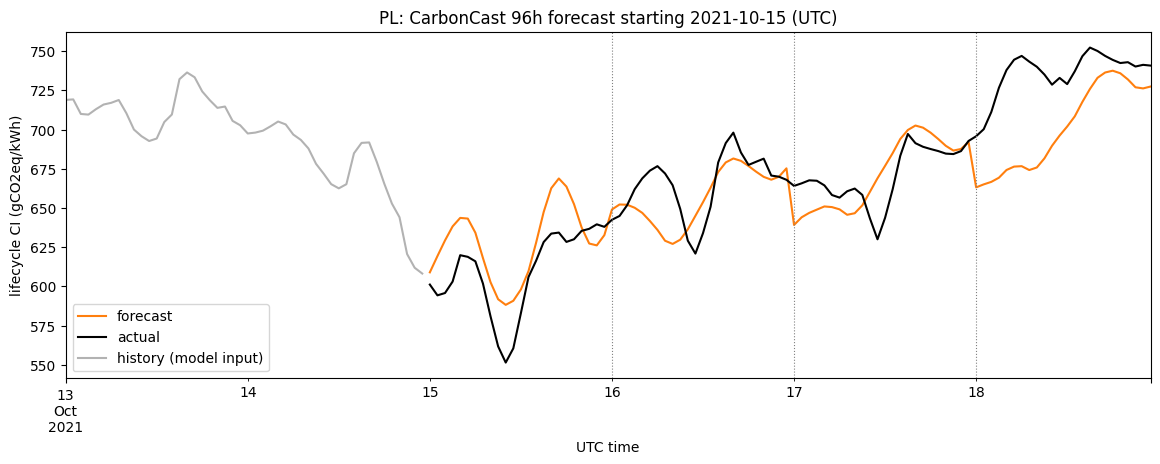

MAPE by forecast day (%): [3.49 2.21 2.07 4.76]


In [10]:
one = forecast_96h(FORECAST_START, model, ctx)
display(one.head())

ax = one.plot(figsize=(14, 4.5), style={"actual": "k-", "forecast": "C1-"})
prev48 = emis["carbon_intensity"].loc[one.index[0] - pd.Timedelta(days=2): one.index[0] - pd.Timedelta(hours=1)]
prev48.plot(ax=ax, color="grey", alpha=.6, label="history (model input)")
for d in range(1, 4):
    ax.axvline(one.index[0] + pd.Timedelta(days=d), color="grey", ls=":", lw=.8)
ax.set_ylabel(f"{CEF_TYPE} CI (gCO2eq/kWh)")
ax.set_title(f"{REGION}: CarbonCast 96h forecast starting {pd.Timestamp(FORECAST_START).date()} (UTC)")
ax.legend(); plt.show()

if one["actual"].notna().all():
    mape_day = [np.mean(np.abs(one.actual[i:i+24] - one.forecast[i:i+24]) / one.actual[i:i+24]) * 100
                for i in range(0, 96, 24)]
    print("MAPE by forecast day (%):", np.round(mape_day, 2))

## 7. Reproduce the evaluation (Jul–Dec 2021)

The original script issues one 96-h forecast every day of the test period and reports MAPE for each forecast day. We do the same (batched, so it takes seconds) and compare with the **baseline** that ships with the repo: CI computed directly from the tier-1 source-production forecasts with the formula from Section 3 (`*_carbon_from_src_*forecasts_<cef>_Jul_Dec_2021.csv`).

In [11]:
def mape(a, p, axis=None):
    return np.mean(np.abs(a - p) / np.maximum(np.abs(a), 1e-7), axis=axis) * 100

def evaluate(model, ctx):
    starts = pd.date_range(ctx["test_start"], periods=NUM_TEST_DAYS, freq="D")   # 181 daily forecasts
    pred = forecast_96h_batch(starts, model, ctx)                                # (181, 96)
    actual = np.stack([ctx["ci"].loc[s: s + pd.Timedelta(hours=95)].values for s in starts])
    return starts, actual, pred

test_starts, actual, pred = evaluate(model, ctx)
test_start, ci = ctx["test_start"], ctx["ci"]

ape_daily = np.stack([mape(actual[:, d*24:(d+1)*24], pred[:, d*24:(d+1)*24], axis=1) for d in range(4)], axis=1)
summary = pd.DataFrame({
    "mean MAPE %":   ape_daily.mean(0),
    "median MAPE %": np.median(ape_daily, 0),
    "p90 MAPE %":    np.percentile(ape_daily, 90, 0),
    "p95 MAPE %":    np.percentile(ape_daily, 95, 0),
}, index=[f"day {d+1} ({d*24}-{(d+1)*24} h)" for d in range(4)])
print(f"{REGION} / {CEF_TYPE}: overall MAPE = {mape(actual, pred):.2f}%,  "
      f"RMSE = {np.sqrt(np.mean((actual - pred) ** 2)):.2f} g/kWh")
display(summary.round(2))

PL / lifecycle: overall MAPE = 4.42%,  RMSE = 37.15 g/kWh


,mean MAPE %,median MAPE %,p90 MAPE %,p95 MAPE %
day 1 (0-24 h),3.25,2.92,5.01,5.49
day 2 (24-48 h),4.25,3.62,6.71,8.17
day 3 (48-72 h),4.80,4.10,7.68,10.45
day 4 (72-96 h),5.38,4.49,8.68,11.70


,CarbonCast,Baseline (formula on tier-1)
day 1 (0-24 h),3.25,2.37
day 2 (24-48 h),4.25,4.16
day 3 (48-72 h),4.80,4.85
day 4 (72-96 h),5.38,5.57


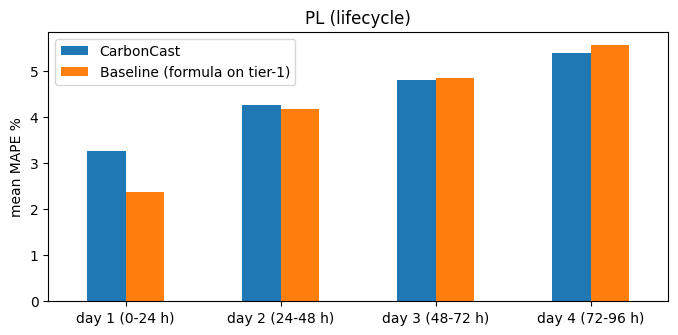

In [12]:
# Baseline: CI calculated from tier-1 source forecasts (file name differs slightly between regions)
base_files = glob.glob(str(REPO / "data" / REGION / f"{REGION}_carbon_from_src*forecasts_{CEF_TYPE}_Jul_Dec_2021.csv"))
if base_files:
    base = read_utc_csv(base_files[0]).reset_index()
    bf = base[f"forecasted_carbon_intensity_{CEF_TYPE}"].values.reshape(-1, 96)
    ba = base[f"actual_carbon_intensity_{CEF_TYPE}"].values.reshape(-1, 96)
    b_daily = [mape(ba[:, d*24:(d+1)*24], bf[:, d*24:(d+1)*24]) for d in range(4)]
    comp = pd.DataFrame({"CarbonCast": ape_daily.mean(0), "Baseline (formula on tier-1)": b_daily},
                        index=summary.index)
    display(comp.round(2))
    comp.plot.bar(figsize=(8, 3.5), rot=0, ylabel="mean MAPE %", title=f"{REGION} ({CEF_TYPE})"); plt.show()
else:
    print("No baseline file found for", REGION, CEF_TYPE)

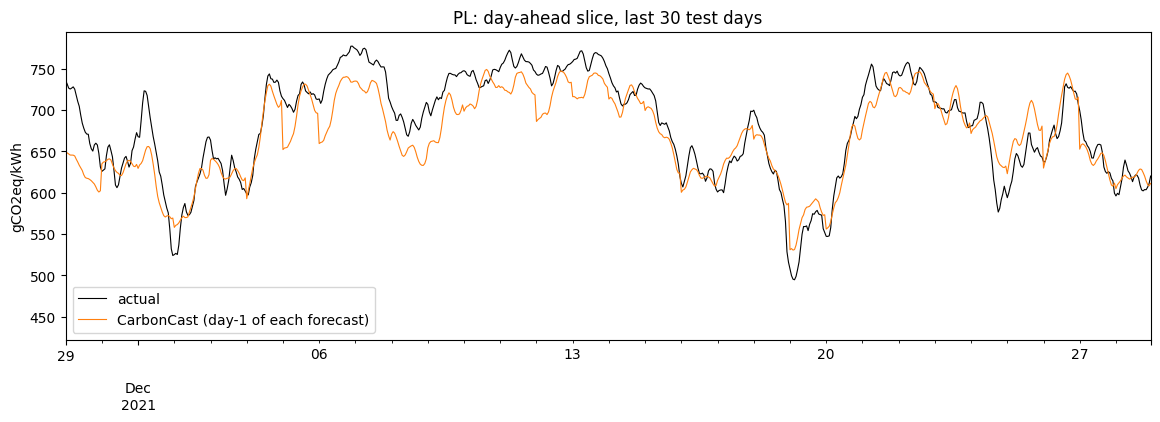

In [13]:
# Continuous view: the day-1 part of every daily forecast, against actuals
day1 = pd.Series(pred[:, :24].ravel(), index=pd.date_range(test_start, periods=NUM_TEST_DAYS * 24, freq="h"))
fig, ax = plt.subplots(figsize=(14, 4))
ci.loc[day1.index].plot(ax=ax, color="k", lw=.8, label="actual")
day1.plot(ax=ax, color="C1", lw=.8, label="CarbonCast (day-1 of each forecast)")
ax.set_xlim(day1.index[-24*30], day1.index[-1])      # last 30 days; remove to see all 6 months
ax.set_ylabel("gCO2eq/kWh"); ax.legend(); ax.set_title(f"{REGION}: day-ahead slice, last 30 test days"); plt.show()

## 8. Save the forecasts

Saved in the same layout as `secondTierForecasts.py` writes (`datetime, carbon_intensity_actual, avg_carbon_intensity_forecast`, 96 rows per forecast, one forecast per day) to `CI_forecast_data/<REGION>/`.

In [ ]:
if SAVE_RESULTS:
    out_dir = REPO / "CI_forecast_data" / REGION
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = pd.DataFrame({
        "datetime": np.concatenate([pd.date_range(s, periods=96, freq="h") for s in test_starts]),
        "carbon_intensity_actual": actual.ravel(),
        "avg_carbon_intensity_forecast": pred.ravel(),
        "forecast_issued_for": np.repeat(test_starts, 96),
    })
    f_eval = out_dir / f"{REGION}_{CEF_TYPE}_96hr_CI_forecasts_notebook.csv"
    rows.to_csv(f_eval, index=False)
    f_one = out_dir / f"{REGION}_{CEF_TYPE}_96hr_forecast_{pd.Timestamp(FORECAST_START).date()}.csv"
    one.to_csv(f_one)
    print("Wrote", f_eval, "\nWrote", f_one)

## 9. All regions at once

Runs the same evaluation for every region with a saved model and collects mean MAPE per forecast day. Each region loads its own data and model. Some regions store timesteps slighlty differently which causes a note to be printed.

In [15]:
def evaluate_region(region, cef_type):
    rc = cfg[region]
    em = read_utc_csv(src_path(rc["LIFECYCLE_CEF_IN_FILE_NAME" if cef_type == "lifecycle" else "DIRECT_CEF_IN_FILE_NAME"]))
    f = read_utc_csv(src_path(rc["FORECAST_IN_FILE_NAME"]))
    c = build_inputs(em, f, rc["NUM_FORECAST_FEATURES"])
    m = load_saved_model(REPO / "saved_second_tier_models" / cef_type / f"{region}.h5")
    _, a, p = evaluate(m, c)
    return [mape(a[:, d*24:(d+1)*24], p[:, d*24:(d+1)*24]) for d in range(4)] + [mape(a, p)]

results = {}
for r in available:
    print("running", r, "...")
    results[r] = evaluate_region(r, CEF_TYPE)
table = pd.DataFrame(results, index=["day 1", "day 2", "day 3", "day 4", "overall"]).T.round(2)
table.columns = [c + " MAPE %" for c in table.columns]
display(table)

running AUS_QLD ...
running BPAT ...
running CISO ...
Note: 1 forecast block(s) carry a timestamp that doesn't match their position (e.g. 2021-12-04 00:00:00); using position, as the original code does.
running DE ...
Note: 1 forecast block(s) carry a timestamp that doesn't match their position (e.g. 2021-12-04 00:00:00); using position, as the original code does.
running ERCO ...
Note: 1 forecast block(s) carry a timestamp that doesn't match their position (e.g. 2021-12-04 00:00:00); using position, as the original code does.
running ES ...
running FPL ...
running ISNE ...
Note: 1 forecast block(s) carry a timestamp that doesn't match their position (e.g. 2021-12-04 00:00:00); using position, as the original code does.
running NL ...
running NYISO ...
running PJM ...
Note: 1 forecast block(s) carry a timestamp that doesn't match their position (e.g. 2021-12-04 00:00:00); using position, as the original code does.
running PL ...
running SE ...
Note: 1 forecast block(s) carry a timestam

,day 1 MAPE %,day 2 MAPE %,day 3 MAPE %,day 4 MAPE %,overall MAPE %
AUS_QLD,4.23,4.40,4.51,4.87,4.50
BPAT,8.38,11.05,12.99,14.98,11.85
CISO,7.97,11.15,12.92,13.88,11.48
DE,8.06,11.40,12.65,14.53,11.66
ERCO,8.52,10.64,11.54,12.57,10.82
ES,10.55,15.56,18.62,20.57,16.33
FPL,2.46,2.92,3.26,3.56,3.05
ISNE,4.98,6.37,7.12,7.35,6.45
NL,6.00,7.49,8.83,9.64,7.99
NYISO,7.28,9.01,9.60,9.76,8.91


## 10. Run the original script instead

The repo's own entry point does the same evaluation (and prints the same day-wise statistics). It must be run from `src/` because its paths are relative, and it needs the pinned TensorFlow/Keras 2.9. Below we write a temporary config containing only your region and run it with the saved model (`-s`).

In [ ]:
import subprocess
tmp_cfg = dict(cfg, REGION=[REGION], WRITE_CI_FORECASTS_TO_FILE="True")
(REPO / "CI_forecast_data" / REGION).mkdir(parents=True, exist_ok=True)
tmp_path = SRC / "_notebook_secondTierConfig.json"
tmp_path.write_text(json.dumps(tmp_cfg, indent=2))
flag = "-l" if CEF_TYPE == "lifecycle" else "-d"
proc = subprocess.run([sys.executable, "secondTierForecasts.py", tmp_path.name, flag, "-s"],
                        cwd=SRC, capture_output=True, text=True)
print(proc.stdout[-4000:])
print(proc.stderr[-2000:])